In [ ]:
# ==================== CÂU a, b, c ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# a) Đọc bộ dữ liệu train, test của MNIST từ Keras
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

# b) In ra kích thước của tập train, test
print("Kích thước tập train:", train_images.shape, train_labels.shape)
print("Kích thước tập test:", test_images.shape, test_labels.shape)

# c) Chuẩn hóa các giá trị pixel của ảnh về đoạn [0,1]
train_images = train_images / 255.0
test_images = test_images / 255.0

Họ tên: Phan Công Trí - MSSV: 6451071080
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Kích thước tập train: (60000, 28, 28) (60000,)
Kích thước tập test: (10000, 28, 28) (10000,)


In [ ]:
# ==================== CÂU d ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

# d) Định nghĩa hàm create_model
def create_model():
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(128, activation='relu'),
        Dropout(0.2),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

print("Đã định nghĩa hàm create_model() thành công!")

Họ tên: Phan Công Trí - MSSV: 6451071080
Đã định nghĩa hàm create_model() thành công!


In [ ]:
# ==================== CÂU e ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

# e) Huấn luyện mô hình bằng k-fold cross validation (k=10)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

models = []
accuracy_per_fold = []
loss_per_fold = []

fold_no = 1
for train_index, val_index in kfold.split(train_images):
    print(f"\n--- Đang huấn luyện Fold {fold_no}/10 ---")
    model_fold = create_model()

    X_train_fold, X_val_fold = train_images[train_index], train_images[val_index]
    y_train_fold, y_val_fold = train_labels[train_index], train_labels[val_index]

    history_fold = model_fold.fit(
        X_train_fold, y_train_fold,
        validation_data=(X_val_fold, y_val_fold),
        epochs=5,
        batch_size=32,
        verbose=0
    )

    # Đánh giá trên tập validation của fold
    scores = model_fold.evaluate(X_val_fold, y_val_fold, verbose=0)
    print(f"Fold {fold_no} - Loss: {scores[0]:.4f} - Accuracy: {scores[1]:.4f}")

    loss_per_fold.append(scores[0])
    accuracy_per_fold.append(scores[1])
    models.append(model_fold)
    fold_no += 1

Họ tên: Phan Công Trí - MSSV: 6451071080

--- Đang huấn luyện Fold 1/10 ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Fold 1 - Loss: 0.0755 - Accuracy: 0.9770

--- Đang huấn luyện Fold 2/10 ---
Fold 2 - Loss: 0.0817 - Accuracy: 0.9758

--- Đang huấn luyện Fold 3/10 ---
Fold 3 - Loss: 0.0878 - Accuracy: 0.9728

--- Đang huấn luyện Fold 4/10 ---
Fold 4 - Loss: 0.0768 - Accuracy: 0.9770

--- Đang huấn luyện Fold 5/10 ---
Fold 5 - Loss: 0.0933 - Accuracy: 0.9723

--- Đang huấn luyện Fold 6/10 ---
Fold 6 - Loss: 0.0778 - Accuracy: 0.9773

--- Đang huấn luyện Fold 7/10 ---
Fold 7 - Loss: 0.0971 - Accuracy: 0.9720

--- Đang huấn luyện Fold 8/10 ---
Fold 8 - Loss: 0.0806 - Accuracy: 0.9773

--- Đang huấn luyện Fold 9/10 ---
Fold 9 - Loss: 0.0831 - Accuracy: 0.9713

--- Đang huấn luyện Fold 10/10 ---
Fold 10 - Loss: 0.0862 - Accuracy: 0.9725


Họ tên: Phan Công Trí - MSSV: 6451071080
Mean Accuracy : 0.9745 (+/- 0.0024)
Mean Loss     : 0.0840 (+/- 0.0068)


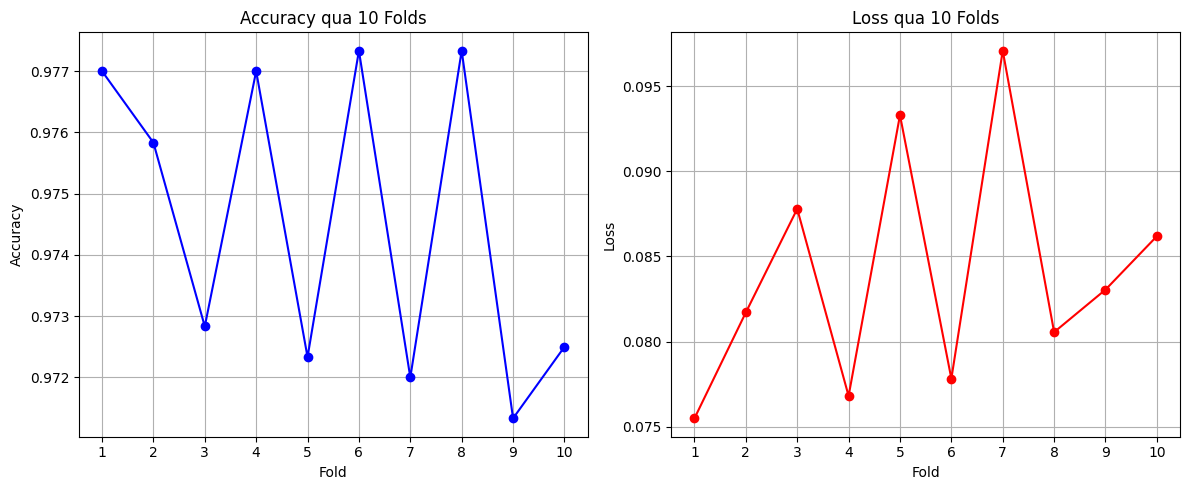

In [ ]:
# ==================== CÂU f, g ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

# f) Tính và in ra Mean Accuracy, Std Accuracy, Mean Loss, Std Loss
print(f"Mean Accuracy : {np.mean(accuracy_per_fold):.4f} (+/- {np.std(accuracy_per_fold):.4f})")
print(f"Mean Loss     : {np.mean(loss_per_fold):.4f} (+/- {np.std(loss_per_fold):.4f})")

# g) Vẽ biểu đồ thể hiện accuracy, loss sau mỗi fold
folds = range(1, 11)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(folds, accuracy_per_fold, marker='o', color='blue')
plt.title('Accuracy qua 10 Folds')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.xticks(folds)
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(folds, loss_per_fold, marker='o', color='red')
plt.title('Loss qua 10 Folds')
plt.xlabel('Fold')
plt.ylabel('Loss')
plt.xticks(folds)
plt.grid(True)

plt.tight_layout()
plt.show()

Họ tên: Phan Công Trí - MSSV: 6451071080
Mô hình tốt nhất thuộc về Fold 6 với Val Accuracy = 0.9773
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

Accuracy trên tập test: 0.9767

Classification Report trên tập test:

              precision    recall  f1-score   support

           0     0.9758    0.9888    0.9823       980
           1     0.9886    0.9903    0.9894      1135
           2     0.9785    0.9680    0.9732      1032
           3     0.9613    0.9832    0.9721      1010
           4     0.9746    0.9786    0.9766       982
           5     0.9840    0.9664    0.9751       892
           6     0.9791    0.9791    0.9791       958
           7     0.9785    0.9737    0.9761      1028
           8     0.9691    0.9671    0.9681       974
           9     0.9770    0.9693    0.9731      1009

    accuracy                         0.9767     10000
   macro avg     0.9767    0.9765    0.9765     10000
weighted avg     0.9767    0.9767    0.9767     10000



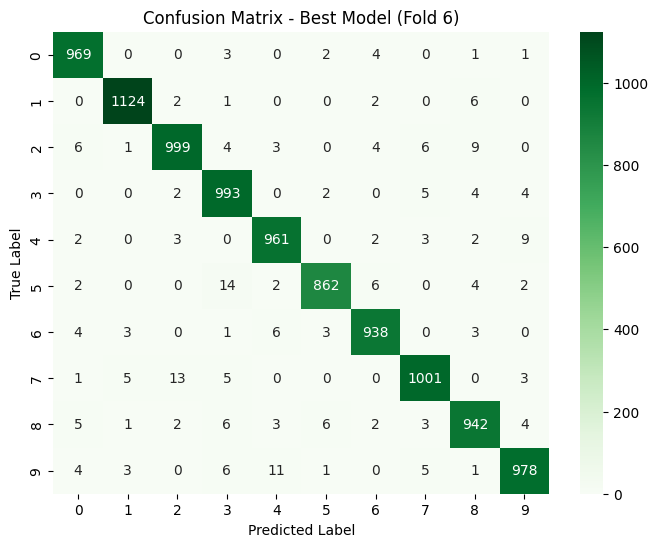

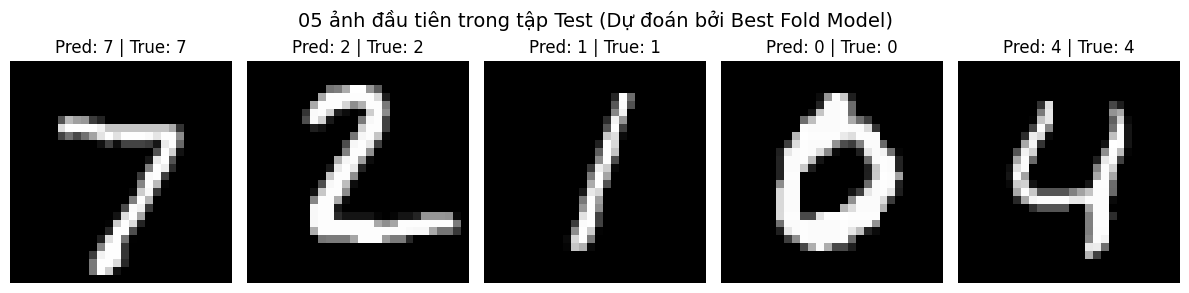

In [ ]:
# ==================== CÂU h, i, j, k, l ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

# h) Chọn mô hình có Accuracy tốt nhất giữa các fold và phân lớp cho tập test
best_fold_idx = np.argmax(accuracy_per_fold)
best_model = models[best_fold_idx]
print(f"Mô hình tốt nhất thuộc về Fold {best_fold_idx + 1} với Val Accuracy = {accuracy_per_fold[best_fold_idx]:.4f}")

y_pred_best = np.argmax(best_model.predict(test_images), axis=1)

# i) Tính và in ra Accuracy của mô hình trên tập test
print("\nAccuracy trên tập test:", accuracy_score(test_labels, y_pred_best))

# j) Tính và in ra Precision, Recall, F1-score của từng lớp và trung bình
print("\nClassification Report trên tập test:\n")
print(classification_report(test_labels, y_pred_best, digits=4))

# k) Hiển thị confusion matrix bằng heat map
cm_best = confusion_matrix(test_labels, y_pred_best)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Greens')
plt.title(f'Confusion Matrix - Best Model (Fold {best_fold_idx + 1})')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# l) In ra kết quả phân lớp của 05 ảnh đầu tiên trong tập test
plt.figure(figsize=(12, 3))
for i in range(5):
    img = np.expand_dims(test_images[i], axis=0)
    pred_label = np.argmax(best_model.predict(img, verbose=0), axis=1)[0]

    plt.subplot(1, 5, i + 1)
    plt.imshow(test_images[i], cmap='gray')
    plt.title(f"Pred: {pred_label} | True: {test_labels[i]}")
    plt.axis('off')
plt.suptitle("05 ảnh đầu tiên trong tập Test (Dự đoán bởi Best Fold Model)", fontsize=14)
plt.tight_layout()
plt.show()